In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from utilsforecast.plotting import plot_series as _plot_series

def plot_series(*args, xlabel=None, ylabel=None, title=None, **kwargs):
    fig = _plot_series(*args, **kwargs)
    if fig is None:
        fig = plt.gcf()
    ax = fig.axes[0] if getattr(fig, "axes", None) else plt.gca()
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if title is not None:
        ax.set_title(title)
    return fig

sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

print("cwd:", os.getcwd())
print("files in data/:", sorted(os.listdir("data"))[:10], "...")

cwd: c:\Users\amelu\OneDrive\Desktop\я\qwant-mentorstvo\quant-research-mentorstvo\sprint-4
files in data/: ['PBS_unparsed.csv', 'ansett.csv', 'prison_population.csv', 'total_cost_df.csv'] ...


In [2]:
pbs = (
    pd.read_csv("data/PBS_unparsed.csv", parse_dates=["Month"])
    [["Month", "Concession", "Type", "ATC1", "ATC2", "Scripts", "Cost"]]
)
pbs


,Month,Concession,Type,ATC1,ATC2,Scripts,Cost
0,1991-07-01,Concessional,Co-payments,A,A01,18228,67877.0
1,1991-08-01,Concessional,Co-payments,A,A01,15327,57011.0
2,1991-09-01,Concessional,Co-payments,A,A01,14775,55020.0
3,1991-10-01,Concessional,Co-payments,A,A01,15380,57222.0
4,1991-11-01,Concessional,Co-payments,A,A01,14371,52120.0
...,...,...,...,...,...,...,...
67591,2008-02-01,General,Safety net,Z,Z,135,1591.0
67592,2008-03-01,General,Safety net,Z,Z,15,276.0
67593,2008-04-01,General,Safety net,Z,Z,11,165.0
67594,2008-05-01,General,Safety net,Z,Z,21,278.0


In [3]:
a10 = pbs.loc[pbs["ATC2"] == "A10"]
a10


,Month,Concession,Type,ATC1,ATC2,Scripts,Cost
1524,1991-07-01,Concessional,Co-payments,A,A10,89733,2092878.0
1525,1991-08-01,Concessional,Co-payments,A,A10,77101,1795733.0
1526,1991-09-01,Concessional,Co-payments,A,A10,76255,1777231.0
1527,1991-10-01,Concessional,Co-payments,A,A10,78681,1848507.0
1528,1991-11-01,Concessional,Co-payments,A,A10,70554,1686458.0
...,...,...,...,...,...,...,...
52339,2008-02-01,General,Safety net,A,A10,10869,530709.0
52340,2008-03-01,General,Safety net,A,A10,1119,51773.0
52341,2008-04-01,General,Safety net,A,A10,721,36289.0
52342,2008-05-01,General,Safety net,A,A10,1947,101233.0


In [4]:
a10 = (
    pbs.loc[pbs["ATC2"] == "A10"]
    .drop(columns=["ATC1", "ATC2"])
)
a10


,Month,Concession,Type,Scripts,Cost
1524,1991-07-01,Concessional,Co-payments,89733,2092878.0
1525,1991-08-01,Concessional,Co-payments,77101,1795733.0
1526,1991-09-01,Concessional,Co-payments,76255,1777231.0
1527,1991-10-01,Concessional,Co-payments,78681,1848507.0
1528,1991-11-01,Concessional,Co-payments,70554,1686458.0
...,...,...,...,...,...
52339,2008-02-01,General,Safety net,10869,530709.0
52340,2008-03-01,General,Safety net,1119,51773.0
52341,2008-04-01,General,Safety net,721,36289.0
52342,2008-05-01,General,Safety net,1947,101233.0


In [5]:
total_cost_df = (
    pbs.loc[pbs["ATC2"] == "A10"]
    .drop(columns=["ATC1", "ATC2"])
    .groupby("Month", as_index=False)
    .agg({"Cost": "sum"})
    .assign(Cost=lambda x: (x["Cost"] / 1e6).round(2))
)
total_cost_df


,Month,Cost
0,1991-07-01,3.53
1,1991-08-01,3.18
2,1991-09-01,3.25
3,1991-10-01,3.61
4,1991-11-01,3.57
...,...,...
199,2008-02-01,21.65
200,2008-03-01,18.26
201,2008-04-01,23.11
202,2008-05-01,22.91


In [6]:
total_cost_df.to_csv("data/total_cost_df.csv", index=False)
print("saved:", os.path.abspath("data/total_cost_df.csv"))


saved: c:\Users\amelu\OneDrive\Desktop\я\qwant-mentorstvo\quant-research-mentorstvo\sprint-4\data\total_cost_df.csv


In [7]:
prison = (
    pd.read_csv("data/prison_population.csv", parse_dates=["Date"])
    .rename(columns={"Date": "Quarter"})
    .sort_values(by=["State", "Gender", "Legal", "Indigenous"])
)
prison


,Quarter,State,Gender,Legal,Indigenous,Count
0,2005-03-01,ACT,Female,Remanded,ATSI,0
64,2005-06-01,ACT,Female,Remanded,ATSI,1
128,2005-09-01,ACT,Female,Remanded,ATSI,0
192,2005-12-01,ACT,Female,Remanded,ATSI,0
256,2006-03-01,ACT,Female,Remanded,ATSI,1
...,...,...,...,...,...,...
2815,2015-12-01,WA,Male,Sentenced,Non-ATSI,2503
2879,2016-03-01,WA,Male,Sentenced,Non-ATSI,2488
2943,2016-06-01,WA,Male,Sentenced,Non-ATSI,2539
3007,2016-09-01,WA,Male,Sentenced,Non-ATSI,2608


In [8]:
q = prison["Quarter"].drop_duplicates().sort_values()
print("min:", q.min(), "max:", q.max())
print("infer_freq:", pd.infer_freq(q))


min: 2005-03-01 00:00:00 max: 2016-12-01 00:00:00
infer_freq: QS-DEC


In [9]:
melsyd_economy = (
    pd.read_csv("data/ansett.csv", parse_dates=["ds"])
    .loc[lambda x: (x["Airports"] == "MEL-SYD")
        & (x["Class"] == "Economy")]
    .rename(columns={"Airports": "unique_id"})
    .assign(y=lambda x: x["y"] / 1000)
)
fig = plot_series(
    df=melsyd_economy, id_col="unique_id", time_col="ds", target_col="y",
    xlabel="Week [1W]", ylabel="Passengers ('000)",
    title="Ansett airlines economy class: Melbourne-Sydney")
fig.tight_layout()
fig.savefig("images/fig_2_1_ansett_time_plot.png", dpi=150)
plt.show()


C:\Users\amelu\AppData\Local\Temp\ipykernel_28876\543356999.py:12: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


In [10]:
w = melsyd_economy["ds"].drop_duplicates().sort_values()
print("min:", w.min(), "max:", w.max())
print("infer_freq:", pd.infer_freq(w))


min: 1987-06-29 00:00:00 max: 1992-11-23 00:00:00
infer_freq: None


In [11]:
fig = plot_series(total_cost_df.assign(unique_id="total_cost"),
    time_col="Month", target_col="Cost",
    xlabel="Month [1M]", ylabel="$ (millions)",
    title="Australian antidiabetic drug sales")
fig.tight_layout()
fig.savefig("images/fig_2_2_total_cost_time_plot.png", dpi=150)
plt.show()


C:\Users\amelu\AppData\Local\Temp\ipykernel_28876\922128800.py:5: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


In [12]:
m = total_cost_df["Month"].drop_duplicates().sort_values()
print("min:", m.min(), "max:", m.max())
print("infer_freq:", pd.infer_freq(m))


min: 1991-07-01 00:00:00 max: 2008-06-01 00:00:00
infer_freq: MS


C:\Users\amelu\AppData\Local\Temp\ipykernel_28876\2318995197.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


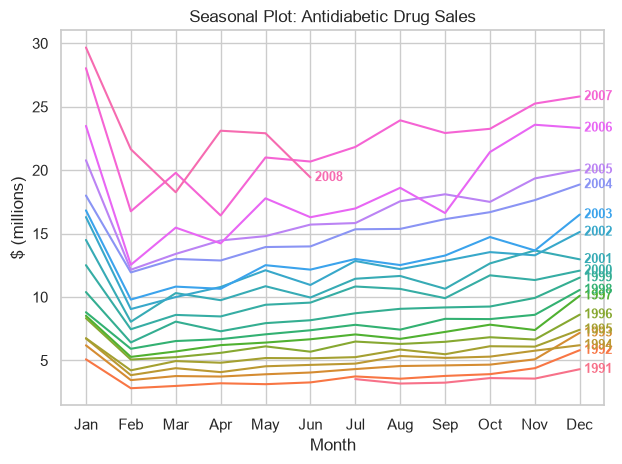

In [13]:
df = total_cost_df.assign(
    Month_name=total_cost_df["Month"].dt.strftime("%b"),
    Year=total_cost_df["Month"].dt.year,
    Month_num=total_cost_df["Month"].dt.month,
)
unique_years = df["Year"].unique()
year_palette = sns.color_palette("husl", n_colors=len(unique_years))
fig, ax = plt.subplots()
sns.lineplot(data=df, x="Month_num", y="Cost",
  hue="Year", palette=year_palette, legend=False, ax=ax)

ax.set(
    title="Seasonal Plot: Antidiabetic Drug Sales",
    xlabel="Month",
    ylabel="$ (millions)",
    xticks=range(1, 13),
    xticklabels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
    ]
)
min_year = unique_years.min()
for year, subset in df.groupby("Year"):
    x = subset["Month_num"].iloc[-1] + .1
    y = subset["Cost"].iloc[-1]
    color = year_palette[year - min_year]
    ax.text(x, y, str(year),
        ha="left", va="center", fontsize=9, weight="bold", color=color)
fig.tight_layout()
fig.savefig("images/fig_2_4_seasonal_plot.png", dpi=150)
fig.show()
